# PORTFOLIO CONSTRUCTION
**Alphaca Capital** · how much weight each edge gets · theory: *Strategy Decorrelation Guide* (TIS · Markowitz 1952), *Workshop 3 · AI without overfitting*, *Walk-Forward Analysis*.

**Reusable workflow:** edit only the `EXPERIMENT` block (section 1), then *Run All*. Each edge is a variant (`<Edge>/variants/<variant>.yaml`) found in `02_strategy_development` or `04_deployment/Approved_Systems`. **No synthetic data**: if an edge cannot be found or run, the notebook stops with an error.

It answers two separate questions:
1. **How is risk split across edges?** → weights `w` (sum to 1).
2. **How much total risk do we run?** → portfolio leverage `L`, capped by the account hard limit.

Output: the final `size_fraction` of each edge + `portfolio.json`, to paste into each variant's YAML (then re-run that edge's notebook 04 for lots).

| § | Step | Guide |
|---|---|---|
| 2 | Find edges, load real daily returns, common window | §3.1 common frequency |
| 3 | Standalone stats | — |
| 4 | Correlation, co-activity, bad days, rolling, JPY factor | §2, §3, §5, §6.2 |
| 5 | 1/√N | §7 |
| 6-7 | Weight schemes and stability (bootstrap) | Markowitz |
| 8 | Risk budget: weights → `size_fraction` | hard limit |
| 9 | Compounding effect | §8 |
| 10 | Stress: correlation → 1 | §2.3 |
| 11 | Walk-forward of the weights | Walk-Forward |
| 12 | PASS / FAIL verdict and save | — |

## DECISION RULE (declared BEFORE looking at results)
With few trades per edge, **expected returns are not identified**. So:
- **Base** = risk-based weights (ERC on a covariance with correlation shrunk to a structural prior).
- A **return tilt** (max-Sharpe on shrunk means) only enters if the bootstrap identifies it (narrow 5-95 interval). Otherwise weights = base.
- Never pick weights at the Sharpe peak: read the **shape** (plateau, not peak).
- `L` comes from the account limit (intrabar Monte Carlo), not from the return you want.
- With N = 2 equal-vol sleeves every risk-based scheme collapses to 50/50; they only diverge for N ≥ 3.

## 1. EXPERIMENT — what is being tested

In [ ]:
# AXI PORTFOLIO V1 ANDRES
# # ======================= EXPERIMENT (the only block you edit) =======================
PORTFOLIO_ID = "portfolio_Axi_v1_Andres"
EDGES        = ["v1_axi_usdjpy", "v1_btcjpy"]   # variant file names (variants/<name>.yaml) or YAML ids
CAPITAL      = 10_000.0
HARD_LIMIT   = 0.08                             # max drawdown the account tolerates
MAX_SIZE     = {"v1_axi_usdjpy": 4.37, "v1_btcjpy": 0.30}   # optional: largest size_fraction each edge was validated at
WHY_UNCORRELATED = ("Different asset (USDJPY vs BTCJPY), logic (bank calendar vs Monday+ATR), horizon (2.5 h vs 24 h). "
                    "SHARED RISK: both long vs JPY; a sharp yen rally hits both.")
# # =====================================================================================

# DARWINEX PORTFOLIO
# # ======================= EXPERIMENT (the only block you edit) =======================
# PORTFOLIO_ID = "portfolio_darwinex"
# EDGES        = ["v1_axi_usdjpy", "v1_qqq"]   # variant file names (variants/<name>.yaml) or YAML ids
# CAPITAL      = 10_000.0
# HARD_LIMIT   = 0.08                          # max drawdown the account tolerates
# MAX_SIZE     = {"v1_axi_usdjpy": 4.37}       # optional: largest size_fraction each edge was validated at (QQQ: no cap declared)
# WHY_UNCORRELATED = ("Different asset class (USDJPY FX vs QQQ equity ETF), logic (Japanese payment-day calendar vs RSI(2) pullback "
#                     "in an uptrend), horizon (2.5 h intraday vs multi-day holds). "
#                     "SHARED RISK: both are long; a risk-off shock hits both (USDJPY falls as the yen rallies while QQQ sells off), "
#                     "and RSI(2) tends to buy into it.")
# # =====================================================================================


In [ ]:
import json, re, hashlib, warnings, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import optimize
warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Method (leave as is; every knob is a degree of freedom: change it -> note it) ----
SEARCH_ROOTS    = {"development": "02_strategy_development", "approved": "04_deployment/Approved_Systems"}
SOURCE_PRIORITY = ["approved", "development"]   # same variant in both roots -> first one wins
FORCE_REFRESH   = False                         # True = regenerate every daily_returns.csv from the engines
PPY             = 365                           # calendar days (BTC trades every day)
JPY_PROXY_CSV   = None                          # optional daily USDJPY CSV (date, close) for the shared JPY factor (4.3)
INTRABAR_FACTOR = 1.25                          # intrabar DD ~ 1.25 x close DD
TARGET_VOL      = 0.10                          # edges scaled to this annual vol before splitting (scale only)
PRIOR_RHO, SHRINK_RHO = 0.20, 0.50              # structural prior for correlation and its weight
MEAN_SHRINK     = 0.50                          # shrink edge means toward the cross-sectional mean (max-Sharpe)
SEED, N_BOOT, N_MC, BLOCK_DAYS, MC_YEARS = 42, 300, 2000, 21, 3
MC_BREACH_MAX   = 0.05                          # max P(touching the hard limit)
CORR_ALERT, CORR_OK, N_MIN_COACTIVE, MIN_OVERLAP_YEARS = 0.50, 0.20, 30, 2.0
W_IDENT_WIDTH, BLEND_IF_IDENT, PLATEAU_TOL, MIN_TRAIN_YEARS = 0.40, 0.50, 0.10, 1.0
HYPOTHESIS = f"Risk-parity base across {', '.join(EDGES)} keeps the account inside -{HARD_LIMIT:.0%}."

# ---- Dark style shared with the Monday Effect notebooks ----
BG, PANEL, GRIDC, TXT, SUB, GREEN, RED, ORANGE, BLUE = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab", "#34d399", "#f0555a", "#f5a524", "#5468ff"
PAL = [BLUE, GREEN, ORANGE, RED, "#a78bfa", "#22d3ee", "#f472b6"]
def dark_ax(ax):
    ax.set_facecolor(PANEL); ax.grid(color=GRIDC, alpha=0.8); ax.tick_params(colors=SUB)
    for s in ax.spines.values(): s.set_visible(False)
def figs(nr=1, nc=1, size=(14, 4.5)):
    fig, ax = plt.subplots(nr, nc, figsize=size, facecolor=BG)
    for a in np.atleast_1d(ax).ravel(): dark_ax(a)
    return fig, ax
def ttl(ax, s): ax.set_title(s, color=TXT, fontweight="bold", loc="left")
def leg(ax, loc="best"): ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc=loc)
def lab(ax, x=None, y=None):
    if x: ax.set_xlabel(x, color=SUB)
    if y: ax.set_ylabel(y, color=SUB)

CHECKS = []
def check(section, name, passed, detail=""):
    st = "SKIP" if passed is None else ("PASS" if bool(passed) else "FAIL")
    e = dict(section=section, name=name, status=st, detail=detail)
    for i, c in enumerate(CHECKS):
        if c["section"] == section and c["name"] == name: CHECKS[i] = e; break
    else: CHECKS.append(e)
    print(f"   [{st}] {name}" + (f"  ->  {detail}" if detail else "")); return st
keys = list(EDGES); N = len(keys)
print(f"{PORTFOLIO_ID} | {N} edges: {keys}")

portfolio_Axi_v1_Andres | 2 edges: ['v1_axi_usdjpy', 'v1_btcjpy']


## 2. FIND EDGES AND LOAD DAILY RETURNS
For each edge the notebook reads `runs/<variant>/daily_returns.csv` (daily mark-to-market return at the variant's `size_fraction`). If the file is missing or the YAML changed, it **runs the edge's real engine once** (same data and rules as its notebooks 03/04) in a separate process and caches the CSV + `size_fraction` next to the run. Validation status is read from `03_validation.json`. Supported engines: Gotobi, Monday Effect; a new engine = one entry in `RECIPES`.

In [ ]:
# ---- 1) Find the edges: <root>/<Edge>/variants/<variant>.yaml  +  <Edge>/runs/<variant>/ ----
def find_dir(rel):
    here = Path.cwd().resolve()
    for base in (here, *here.parents):
        for r in (rel, rel.replace("Systems", "Sustems")):      # tolerates the 'Sustems' typo folder
            if (base / r).is_dir(): return base / r
    return None
ROOTS = {k: find_dir(v) for k, v in SEARCH_ROOTS.items()}

def read_yaml(p):
    import yaml; return yaml.safe_load(p.read_text()) or {}

rows = []
for src, base in ROOTS.items():
    for y in sorted(base.glob("*/variants/*.yaml")) if base else []:
        edge = y.parent.parent; cfg = read_yaml(y)
        rows.append(dict(source=src, id=str(cfg.get("id", y.stem)), variant=y.stem, edge=edge.name, edge_dir=edge, run_dir=edge / "runs" / y.stem, yaml=y))
CAT = pd.DataFrame(rows, columns=["source", "id", "variant", "edge", "edge_dir", "run_dir", "yaml"])
print("Roots:", {k: (str(v) if v else "NOT FOUND") for k, v in ROOTS.items()})
if CAT.empty: raise FileNotFoundError("No variants/*.yaml found under SEARCH_ROOTS. Run this notebook from inside research_development.")

def resolve(name):
    low = name.lower()
    for m in (CAT[CAT.variant.str.lower() == low], CAT[CAT.id.str.lower() == low], CAT[(CAT.edge + "/" + CAT.variant).str.lower() == low]):
        for s in SOURCE_PRIORITY:
            mm = m[m.source == s]
            if len(mm): return mm.iloc[0]
    raise KeyError(f"'{name}' is not a variant or YAML id. Available: {sorted(CAT.variant.unique())}")

# ---- 2) Daily returns: read runs/<variant>/daily_returns.csv, or build it ONCE from the real engine ----
# The engines are run in a fresh Python process (both ship a variant_config.py with the same name; they would clash in one kernel).
RECIPES = {
"gotobi_engine.py": """
import gotobi_engine as eng, variant_config as vc
vc.EDGE_DIR = Path(EDGE); cfg = vc.load_variant(VARIANT)
eng.set_engine_defaults(**cfg["engine_defaults"]); eng.apply_cfd_preset(cfg["account"]["cfd_preset"]); eng.set_engine_defaults(account_ccy=cfg["account"]["ccy"])
INS = cfg["instrument"]; FRAC = float(cfg["risk"]["size_fraction"])
df = eng.load_data(start=INS["start"], end=INS.get("end")); trades = eng.run_gotobi_backtest(df)
ret = eng.daily_returns(df, trades, FRAC)
""",
"monday_effect_engine.py": """
import monday_effect_engine as eng, variant_config as vc
vc.EDGE_DIR = Path(EDGE); cfg = vc.load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {})); P = cfg["params"]
_p = Path(eng.ENGINE_DEFAULTS["csv_path"])
if not _p.is_absolute() and not _p.exists():          # configured path does not resolve: find (or build) the UTC file by symbol + timeframe
    _pre = "_".join(_p.stem.lower().split("_")[:2])   # e.g. "btcjpy_h1"
    _hit = _raw = None
    for b in Path(EDGE).resolve().parents:
        d = b / "data" / _p.parent.name               # same source folder as configured (axi / darwinex / ...)
        if not d.is_dir(): continue
        utc = sorted(x for x in d.rglob("*.csv") if x.name.lower().startswith(_pre) and "utc" in x.name.lower())
        if utc: _hit = utc[-1]; break
        rawc = sorted(x for x in d.glob("*.csv") if x.name.lower().startswith(_pre))
        if rawc: _raw, _hit = rawc[-1], d / _p.name; break
    if _hit is None: raise FileNotFoundError("no '" + _pre + "*.csv' in any <ancestor>/data/" + _p.parent.name + " folder")
    if not _hit.exists():                             # one-time conversion of the raw MetaTrader export to UTC (replaces convert_axi_h1.py)
        r = pd.read_csv(_raw, sep=None, engine="python"); r.columns = [c.strip("<>").lower() for c in r.columns]
        t = pd.to_datetime(r["date"].astype(str) + " " + r["time"].astype(str), format="%Y.%m.%d %H:%M:%S")
        # MT5 server time = New York time + 7 h (GMT+2 winter / GMT+3 summer, US DST) -> UTC
        utc_t = (t - pd.Timedelta(hours=7)).dt.tz_localize("America/New_York", ambiguous="NaT", nonexistent="shift_forward").dt.tz_convert("UTC").dt.tz_localize(None)
        o = pd.DataFrame({"time": utc_t, "open": r["open"], "high": r["high"], "low": r["low"], "close": r["close"], "volume": r["tickvol"] if "tickvol" in r else r["vol"]})
        o = o.dropna(subset=["time"]).sort_values("time").drop_duplicates("time"); o.to_csv(_hit, index=False)
        print("converted", _raw.name, "->", _hit, "|", len(o), "rows |", o.time.iloc[0], "->", o.time.iloc[-1])
    eng.ENGINE_DEFAULTS["csv_path"] = str(_hit); print("data file:", _hit)
RULES = dict(vol_mode=P["vol_mode"], atr_pctl=float(P["atr_pctl"]), atr_len=int(P["atr_len"]), skip_first_monday=P["skip_first_monday"],
             entry_hour=P["entry_hour"], hold_bars=P["hold_bars"], cost_bps_per_side=P["cost_bps_per_side"])
raw = eng.load_data(cfg["instrument"]["ticker"], start=cfg["instrument"]["start"])
df = eng.prepare(raw, atr_len=RULES["atr_len"], entry_hour=RULES["entry_hour"]); trades = eng.run_monday_backtest(df, **RULES)
FRAC = float(eng.ENGINE_DEFAULTS["size_fraction"]); ret = eng.daily_returns(df, trades, sizing="fraction")
""",
"rsi2_engine.py": """
sys.path.insert(0, str(Path(EDGE) / "rsi2_engine"))   # same import order as the RSI2 notebooks
import rsi2_engine as eng, variant_config as vc
vc.EDGE_DIR = Path(EDGE); cfg = vc.load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
_cp = eng.ENGINE_DEFAULTS.get("csv_path")
if _cp and not Path(_cp).is_absolute() and not Path(_cp).exists():      # relative data path does not resolve from here: look in <ancestor>/data/**
    _hit = next((h for b in Path(EDGE).resolve().parents if (b / "data").is_dir() for h in (b / "data").rglob(Path(_cp).name)), None)
    if _hit is None: raise FileNotFoundError("data file " + Path(_cp).name + " not found in any <ancestor>/data folder of " + EDGE)
    eng.ENGINE_DEFAULTS["csv_path"] = str(_hit)
P = cfg["params"]
raw = eng.load_data(cfg["instrument"]["ticker"], start=cfg["instrument"]["start"])
df = eng.prepare(raw, sma_len=P["sma_len"])
trades = eng.run_rsi2_backtest(df, rsi_thr=P["rsi_thr"], sma_len=P["sma_len"], exit_mode=P["exit_mode"], slip_bps_per_side=P["slip_bps_per_side"])
FRAC = 1.0                                             # official run = 1% risk ATR sizing; size_fraction here = multiple of that sizing
ret = eng.daily_returns(df, trades, sizing="atr")
""",
}
RUNNER = """
import sys, json
from pathlib import Path
import pandas as pd
EDGE, VARIANT, OUT, YSHA = {edge!r}, {variant!r}, {out!r}, {ysha!r}
sys.path.insert(0, EDGE)
for b in (Path(EDGE).resolve(), *Path(EDGE).resolve().parents):
    if (b / "utils" / "utils").is_dir(): sys.path.insert(0, str(b / "utils" / "utils")); break
{recipe}
pd.Series(ret, name="ret").to_csv(OUT, index_label="date")
Path(OUT + ".meta.json").write_text(json.dumps(dict(frac=FRAC, yaml_sha=YSHA)))
"""

def get_returns(row):
    csv = row.run_dir / "daily_returns.csv"; meta = Path(str(csv) + ".meta.json")
    ysha = hashlib.sha1(row.yaml.read_bytes()).hexdigest()[:10]
    fresh = csv.exists() and meta.exists() and json.loads(meta.read_text()).get("yaml_sha") == ysha and not FORCE_REFRESH
    if not fresh:
        recipe = next((r for f, r in RECIPES.items() if any(p.is_file() for p in (row.edge_dir / f, row.edge_dir / Path(f).stem / f))), None)
        if recipe is None: raise RuntimeError(f"{row.variant}: no engine recipe for {row.edge_dir.name}. Add one to RECIPES or drop a daily_returns.csv in {row.run_dir}")
        print(f"   building {row.variant} from its engine (one time; cached afterwards)...")
        row.run_dir.mkdir(parents=True, exist_ok=True)
        code = RUNNER.format(edge=str(row.edge_dir), variant=row.variant, out=str(csv), ysha=ysha, recipe=recipe)
        # engines resolve relative data paths (../../data/...) from cwd: use the 02_strategy_development copy of the edge folder, which has that depth
        dev = ROOTS["development"]; cwd = next((d for d in (dev / row.edge_dir.name, row.edge_dir) if d.is_dir()), row.edge_dir)
        p = subprocess.run([sys.executable, "-c", code], cwd=cwd, capture_output=True, text=True)
        if p.returncode: raise RuntimeError(f"{row.variant}: engine failed\n{p.stderr[-3000:]}")
    s = pd.read_csv(csv, index_col=0, parse_dates=True).iloc[:, 0].astype(float)
    s.index = pd.to_datetime(s.index)
    if getattr(s.index, "tz", None) is not None: s.index = s.index.tz_localize(None)
    s = s.groupby(s.index.normalize()).sum()
    return s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="D")).fillna(0.0), float(json.loads(meta.read_text())["frac"])

def validation_status(run_dir):
    f = run_dir / "03_validation.json"
    if not f.exists(): return "03_validation.json not found"
    j = json.loads(f.read_text())
    hit = next((f"{k}={j[k]}" for k in ("overall", "verdict", "status", "passed") if k in j), None)
    return hit or f"see {f.name}"

SL, raw = {}, {}
for k in keys:
    row = resolve(k); raw[k], frac = get_returns(row)
    SL[k] = dict(name=row.id, frac=frac, max_frac=MAX_SIZE.get(k, np.inf), status=validation_status(row.run_dir), path=row.run_dir / "daily_returns.csv", source=row.source)
display(pd.DataFrame({k: dict(id=v["name"], source=v["source"], size_fraction=v["frac"], days=len(raw[k]), first=raw[k].index[0].date(), last=raw[k].index[-1].date()) for k, v in SL.items()}).T)

OUT_DIR = Path.cwd() / "runs" / PORTFOLIO_ID; OUT_DIR.mkdir(parents=True, exist_ok=True)   # next to this notebook

unit = {k: raw[k] / SL[k]["frac"] for k in keys}                 # return per 1.0x nominal exposure
first = {k: r[r != 0].index[0] for k, r in raw.items()}; last = {k: r[r != 0].index[-1] for k, r in raw.items()}
START, END = max(first.values()), min(last.values())             # common window: all edges already trading
U = pd.concat(unit, axis=1).loc[START:END].fillna(0.0); YEARS = len(U) / PPY
print(f"Common window: {START:%Y-%m-%d} -> {END:%Y-%m-%d} | {len(U)} days | {YEARS:.2f} years")
check("2. Data", f"common window >= {MIN_OVERLAP_YEARS:g} years", YEARS >= MIN_OVERLAP_YEARS, f"{YEARS:.2f}")

Roots: {'development': '/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development', 'approved': '/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/04_deployment/Approved_Systems'}


,id,source,size_fraction,days,first,last
v1_axi_usdjpy,GOTOBI.usdjpy.cfd.v1,development,2.5,3593,2017-01-02,2026-11-03
v1_btcjpy,MONDAY.btcjpy.cfd.v1,approved,0.2,1600,2022-06-17,2026-11-02


Common window: 2023-01-16 -> 2026-08-24 | 1317 days | 3.61 years
   [PASS] common window >= 2 years  ->  3.61


'PASS'

## 3. STANDALONE STATS
Same metrics for all edges on calendar days (PPY=365); each edge's own notebook may annualise with 252, so Sharpe can differ slightly.

In [ ]:
def perf(r, ppy=PPY):
    r = r.astype(float); eq = (1 + r).cumprod(); yrs = len(r) / ppy; mu, sd = r.mean() * ppy, r.std() * np.sqrt(ppy)
    return dict(years=yrs, ann_ret=mu, vol=sd, sharpe=mu / sd if sd > 0 else np.nan, cagr=eq.iloc[-1] ** (1 / yrs) - 1,
                maxdd=(eq / eq.cummax() - 1).min(), active_days=(r != 0).mean())
F = {"years": "{:.2f}", "ann_ret": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "cagr": "{:.1%}", "maxdd": "{:.2%}", "active_days": "{:.1%}"}
print("A) Full history of each edge, at its configured size_fraction"); display(pd.DataFrame({k: perf(raw[k]) for k in keys}).T.style.format(F))
print("B) Common window only, same size");                              display(pd.DataFrame({k: perf(U[k] * SL[k]["frac"]) for k in keys}).T.style.format(F))

A) Full history of each edge, at its configured size_fraction


,years,ann_ret,vol,sharpe,cagr,maxdd,active_days
v1_axi_usdjpy,9.84,4.3%,3.5%,1.24,4.4%,-4.23%,19.4%
v1_btcjpy,4.38,3.8%,2.6%,1.47,3.9%,-2.20%,3.4%


B) Common window only, same size


,years,ann_ret,vol,sharpe,cagr,maxdd,active_days
v1_axi_usdjpy,3.61,3.5%,3.8%,0.90,3.4%,-4.23%,19.4%
v1_btcjpy,3.61,4.6%,2.9%,1.62,4.7%,-2.20%,4.1%


## 4. CORRELATION (Guide §2, §3, §5)
Returns, never equity levels · common frequency (daily / weekly / monthly) · `> 0.50` red alert, `0.20-0.50` watch, `< 0.20` good · structural vs parametric.

**Trap for sparse edges:** a series full of zeros correlates ≈ 0 *by construction*. So co-activity and the number of overlapping periods are reported; with too few co-active weeks the number proves nothing.

,freq,pair,corr,ci5,ci95,periods,both_active
0,daily,v1_axi_usdjpy / v1_btcjpy,+0.01,-0.02,+0.05,1317,11
1,weekly,v1_axi_usdjpy / v1_btcjpy,+0.07,-0.06,+0.21,189,52
2,monthly,v1_axi_usdjpy / v1_btcjpy,-0.01,-0.28,+0.18,44,27


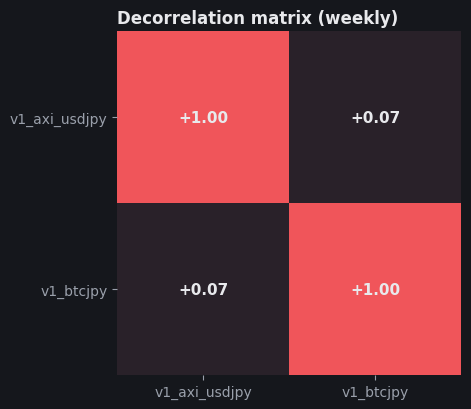

   [PASS] v1_axi_usdjpy/v1_btcjpy: weekly corr estimable (>= 30 co-active weeks)  ->  52 co-active weeks
   [PASS] v1_axi_usdjpy/v1_btcjpy: weekly corr < 0.5  ->  +0.07 (CI90 -0.06..+0.21)
   [PASS] structural reason declared (WHY_UNCORRELATED)  ->  see EXPERIMENT


'PASS'

In [ ]:
def at_freq(df, f): return df if f == "D" else (1 + df).resample(f).prod() - 1
def block_idx(n, size, block, rng, nsim):
    nb = int(np.ceil(size / block)); st = rng.integers(0, n, size=(nsim, nb))
    return ((st[:, :, None] + np.arange(block)[None, None, :]) % n).reshape(nsim, -1)[:, :size]
R = U * pd.Series({k: SL[k]["frac"] for k in keys})              # returns at configured size (what runs today)
rng = np.random.default_rng(SEED); pairs = [(a, b) for i, a in enumerate(keys) for b in keys[i + 1:]]
rows, mats = [], {}
for f, nm, blk in (("D", "daily", BLOCK_DAYS), ("W", "weekly", 4), ("MS", "monthly", 2)):
    X = at_freq(R, f); mats[nm] = X.corr(); A = X != 0
    for a, b in pairs:
        bi = block_idx(len(X), len(X), min(blk, len(X)), rng, 500)
        bs = [pd.Series(X[a].values[i]).corr(pd.Series(X[b].values[i])) for i in bi]
        rows.append(dict(freq=nm, pair=f"{a} / {b}", corr=X[a].corr(X[b]), ci5=np.nanpercentile(bs, 5), ci95=np.nanpercentile(bs, 95), periods=len(X), both_active=int((A[a] & A[b]).sum())))
ct = pd.DataFrame(rows); display(ct.style.format({"corr": "{:+.2f}", "ci5": "{:+.2f}", "ci95": "{:+.2f}"}))
fig, ax = figs(1, 1, (5.2, 4.2)); Cw = mats["weekly"]
im = ax.imshow(Cw.values, cmap=LinearSegmentedColormap.from_list("c", [GREEN, PANEL, RED]), vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(N)); ax.set_xticklabels(keys, color=SUB); ax.set_yticks(range(N)); ax.set_yticklabels(keys, color=SUB)
for i in range(N):
    for j in range(N): ax.text(j, i, f"{Cw.values[i, j]:+.2f}", ha="center", va="center", color=TXT, fontsize=11, fontweight="bold")
ttl(ax, "Decorrelation matrix (weekly)"); plt.tight_layout(); plt.show()
for a, b in pairs:
    w = ct[(ct.freq == "weekly") & (ct.pair == f"{a} / {b}")].iloc[0]
    check("4. Correlation", f"{a}/{b}: weekly corr estimable (>= {N_MIN_COACTIVE} co-active weeks)", w.both_active >= N_MIN_COACTIVE,
          f"{w.both_active} co-active weeks" + ("" if w.both_active >= N_MIN_COACTIVE else f": the {w['corr']:+.2f} does NOT prove decorrelation (zeros dominate)"))
    check("4. Correlation", f"{a}/{b}: weekly corr < {CORR_ALERT}", w["corr"] < CORR_ALERT, f"{w['corr']:+.2f} (CI90 {w.ci5:+.2f}..{w.ci95:+.2f})")
check("4. Correlation", "structural reason declared (WHY_UNCORRELATED)", bool(WHY_UNCORRELATED.strip()), "see EXPERIMENT")

### 4.2 Co-activity and bad days (Guide §6.2)
`lift = P(both active) / (P(A)·P(B))`: ≈ 1 independent in calendar, > 1 tend to coincide. Then the worst days of each edge and what the others did that day.

In [ ]:
Act, Loss = (R != 0), (R < 0); rows = []
for a, b in pairs:
    pa, pb, pab = Act[a].mean(), Act[b].mean(), (Act[a] & Act[b]).mean()
    rows.append(dict(pair=f"{a} / {b}", P_A=pa, P_B=pb, P_both=pab, lift=pab / (pa * pb) if pa * pb else np.nan,
                     joint_loss_days=int((Loss[a] & Loss[b]).sum()), expected_if_indep=Loss[a].sum() * Loss[b].mean()))
display(pd.DataFrame(rows).style.format({"P_A": "{:.1%}", "P_B": "{:.1%}", "P_both": "{:.2%}", "lift": "{:.2f}", "expected_if_indep": "{:.1f}"}))
for k in keys:
    d = R[k].nsmallest(8); t = R.loc[d.index].copy(); t["others_also_lose"] = (t.drop(columns=k) < 0).any(axis=1)
    print(f"Worst days of {k} (configured size)"); display(t.style.format({c: "{:+.3%}" for c in keys}))

,pair,P_A,P_B,P_both,lift,joint_loss_days,expected_if_indep
0,v1_axi_usdjpy / v1_btcjpy,19.4%,4.1%,0.84%,1.05,2,1.2


Worst days of v1_axi_usdjpy (configured size)


,v1_axi_usdjpy,v1_btcjpy,others_also_lose
2023-12-08 00:00:00,-1.921%,+0.000%,False
2024-08-05 00:00:00,-1.906%,+0.000%,False
2024-11-29 00:00:00,-1.478%,+0.000%,False
2023-02-24 00:00:00,-1.046%,+0.000%,False
2025-04-10 00:00:00,-0.926%,+0.000%,False
2025-06-13 00:00:00,-0.852%,+0.000%,False
2025-07-10 00:00:00,-0.788%,+0.000%,False
2024-07-25 00:00:00,-0.780%,+0.000%,False


Worst days of v1_btcjpy (configured size)


,v1_axi_usdjpy,v1_btcjpy,others_also_lose
2023-12-11 00:00:00,+0.000%,-1.079%,False
2024-11-25 00:00:00,-0.266%,-1.042%,True
2023-01-30 00:00:00,+0.000%,-0.705%,False
2025-03-10 00:00:00,-0.606%,-0.619%,True
2024-04-15 00:00:00,+0.273%,-0.615%,False
2024-12-09 00:00:00,+0.000%,-0.604%,False
2023-03-27 00:00:00,+0.000%,-0.588%,False
2024-07-29 00:00:00,+0.000%,-0.497%,False


### 4.3 Rolling correlation and shared JPY factor
Guide §2.3: correlation is not constant. The JPY block is the most serious structural objection (both edges are long vs the yen); set `JPY_PROXY_CSV` to activate it.

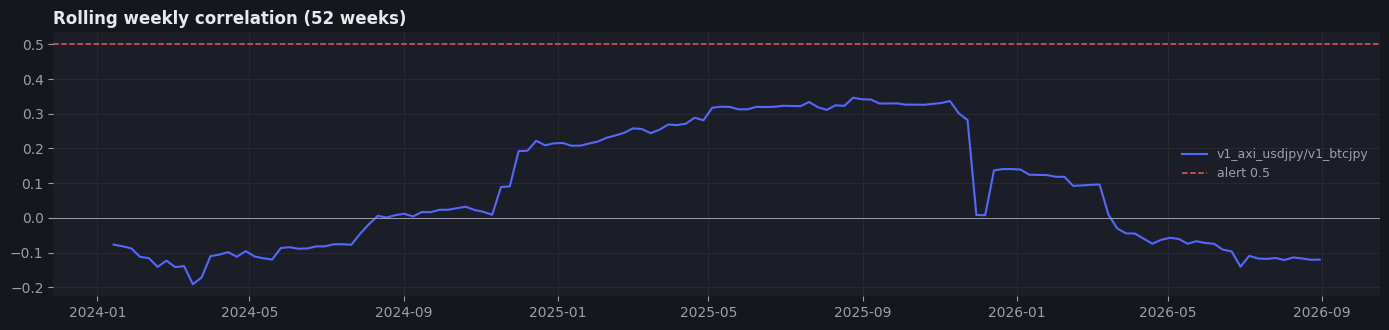

   [SKIP] shared JPY factor measured  ->  set JPY_PROXY_CSV


In [ ]:
Wk = at_freq(R, "W")
if len(Wk) >= 70:
    fig, ax = figs(1, 1, (14, 3.4))
    for i, (a, b) in enumerate(pairs): ax.plot(Wk.index, Wk[a].rolling(52).corr(Wk[b]), color=PAL[i % len(PAL)], lw=1.5, label=f"{a}/{b}")
    ax.axhline(CORR_ALERT, color=RED, ls="--", lw=1.1, label=f"alert {CORR_ALERT}"); ax.axhline(0, color=SUB, lw=.7)
    ttl(ax, "Rolling weekly correlation (52 weeks)"); leg(ax); plt.tight_layout(); plt.show()
else: print(f"Only {len(Wk)} weeks: too short for a 52-week rolling correlation.")

if JPY_PROXY_CSV is None:
    check("4. Correlation", "shared JPY factor measured", None, "set JPY_PROXY_CSV")
else:
    fx = pd.read_csv(JPY_PROXY_CSV, index_col=0, parse_dates=True).iloc[:, 0].astype(float)
    fx.index = (fx.index.tz_localize(None) if getattr(fx.index, "tz", None) else fx.index).normalize()
    jr = fx.pct_change().reindex(R.index).fillna(0.0); rally = jr <= jr[jr != 0].quantile(0.05)
    t = pd.DataFrame({k: dict(corr_vs_USDJPY_active=R.loc[Act[k], k].corr(jr[Act[k]]) if Act[k].sum() > 5 else np.nan,
                              active_in_yen_rally=int((Act[k] & rally).sum()), mean_pnl_in_rally=R.loc[Act[k] & rally, k].mean(),
                              mean_pnl_otherwise=R.loc[Act[k] & ~rally, k].mean()) for k in keys}).T
    display(t.style.format({"corr_vs_USDJPY_active": "{:+.2f}", "mean_pnl_in_rally": "{:+.3%}", "mean_pnl_otherwise": "{:+.3%}"}))
    check("4. Correlation", "shared JPY factor measured", True, "if all edges lose in yen rallies, the decorrelation is parametric")

## 5. HOW MANY EDGES: 1/√N (Guide §7)
`σ_portfolio / σ_edge = √(1/N + (1 − 1/N)·ρ)`. *"3 truly different systems beat 15 cousins."*

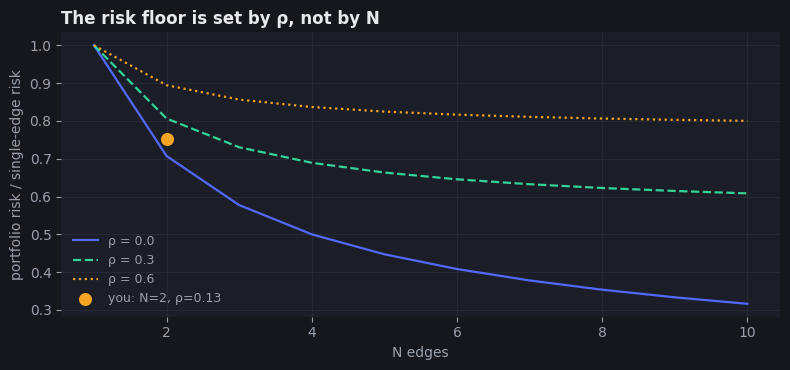

measured weekly ρ = +0.07 | shrunk ρ (prior 0.2, λ=0.5) = 0.13 | relative risk at N=2: 0.75 (floor: 0.36)


In [ ]:
rr = lambda n, rho: np.sqrt(1 / n + (1 - 1 / n) * rho)
off = ~np.eye(N, dtype=bool); rho_hat = np.nanmean(mats["weekly"].values[off]); rho_use = (1 - SHRINK_RHO) * rho_hat + SHRINK_RHO * PRIOR_RHO
ns = np.arange(1, 11); fig, ax = figs(1, 1, (8, 3.8))
for i, (rho, ls) in enumerate(((0.0, "-"), (0.3, "--"), (0.6, ":"))): ax.plot(ns, rr(ns, rho), ls, color=PAL[i], lw=1.6, label=f"ρ = {rho}")
ax.scatter([N], [rr(N, rho_use)], color=ORANGE, s=70, zorder=5, label=f"you: N={N}, ρ={rho_use:.2f}")
ttl(ax, "The risk floor is set by ρ, not by N"); lab(ax, "N edges", "portfolio risk / single-edge risk"); leg(ax); plt.tight_layout(); plt.show()
print(f"measured weekly ρ = {rho_hat:+.2f} | shrunk ρ (prior {PRIOR_RHO}, λ={SHRINK_RHO}) = {rho_use:.2f} | relative risk at N={N}: {rr(N, rho_use):.2f} (floor: {np.sqrt(max(rho_use, 0)):.2f})")

## 6. WEIGHT SCHEMES
**Normalise:** each edge is scaled to `TARGET_VOL` by `SCALE_i = TARGET_VOL / σ_i`; weights `w` are then a **risk split** and the final size is `exposure_i = L · w_i · SCALE_i`.
Schemes: `equal_vol` · `erc` (equal risk contribution, shrunk covariance) · `min_var` · `max_sharpe_shrunk` · `as_configured` (reference: what runs today).

In [ ]:
sig_u = U.std() * np.sqrt(PPY); SCALE = TARGET_VOL / sig_u; V = U * SCALE
mu_hat, cov_hat = V.mean().values * PPY, V.cov().values * PPY
def shrink_cov(cov, prior=PRIOR_RHO, lam=SHRINK_RHO):
    d = np.sqrt(np.diag(cov)); rho = cov / np.outer(d, d); o = ~np.eye(len(d), dtype=bool); rho[o] = (1 - lam) * rho[o] + lam * prior
    return rho * np.outer(d, d)
def _solve(fun, n):
    r = optimize.minimize(fun, np.full(n, 1 / n), bounds=[(0, 1)] * n, method="SLSQP", constraints=({"type": "eq", "fun": lambda w: w.sum() - 1},))
    w = np.clip(r.x, 0, None); return w / w.sum()
def w_equal(mu, cov):  return np.full(len(mu), 1 / len(mu))
def w_minvar(mu, cov): return _solve(lambda w: w @ cov @ w, len(mu))
def w_erc(mu, cov):
    n = len(mu)
    def f(w): rc = w * (cov @ w); rc = rc / rc.sum(); return ((rc - 1 / n) ** 2).sum()
    return _solve(f, n)
def w_maxsr(mu, cov):
    m = (1 - MEAN_SHRINK) * mu + MEAN_SHRINK * mu.mean(); return _solve(lambda w: -(w @ m) / np.sqrt(w @ cov @ w), len(mu))
SCHEMES = {"equal_vol": w_equal, "erc": w_erc, "min_var": w_minvar, "max_sharpe_shrunk": w_maxsr}
cov_s = shrink_cov(cov_hat); W = pd.DataFrame({n: f(mu_hat, cov_s) for n, f in SCHEMES.items()}, index=keys)
cfg_exp = np.array([SL[k]["frac"] for k in keys]); cfg_w = cfg_exp / SCALE.values; W["as_configured"] = cfg_w / cfg_w.sum()
pm = lambda w, L=1.0: perf(pd.Series(L * V.values @ np.asarray(w), index=V.index))
print("Risk weights by scheme (sum to 1)"); display(W.style.format("{:.1%}"))
print("Common-window performance, normalised space (L=1). Descriptive, NOT a selection criterion:")
display(pd.DataFrame({n: pm(W[n]) for n in W.columns}).T[["ann_ret", "vol", "sharpe", "cagr", "maxdd"]].style.format(F))
print("Nominal exposure each edge needs to sit at TARGET_VOL:", {k: f"{SCALE[k]:.2f}x" for k in keys}, "| configured today:", {k: f"{SL[k]['frac']:.2f}x" for k in keys})
print("=> risk split implied by today's sizes:", {k: f"{v:.0%}" for k, v in zip(keys, W['as_configured'])})

Risk weights by scheme (sum to 1)


,equal_vol,erc,min_var,max_sharpe_shrunk,as_configured
v1_axi_usdjpy,50.0%,50.0%,50.0%,41.2%,57.1%
v1_btcjpy,50.0%,50.0%,50.0%,58.8%,42.9%


Common-window performance, normalised space (L=1). Descriptive, NOT a selection criterion:


,ann_ret,vol,sharpe,cagr,maxdd
equal_vol,12.6%,7.1%,1.77,13.2%,-5.80%
erc,12.6%,7.1%,1.77,13.2%,-5.80%
min_var,12.6%,7.1%,1.77,13.2%,-5.80%
max_sharpe_shrunk,13.2%,7.2%,1.83,13.9%,-5.84%
as_configured,12.1%,7.2%,1.68,12.6%,-6.41%


Nominal exposure each edge needs to sit at TARGET_VOL: {'v1_axi_usdjpy': '6.55x', 'v1_btcjpy': '0.70x'} | configured today: {'v1_axi_usdjpy': '2.50x', 'v1_btcjpy': '0.20x'}
=> risk split implied by today's sizes: {'v1_axi_usdjpy': '57%', 'v1_btcjpy': '43%'}


### 6.1 Shape, not peak (N = 2 only)
Sweep the weight of the 2nd edge. If the Sharpe curve is flat over a wide range, the exact weight does not matter and the centre of the plateau is preferred.

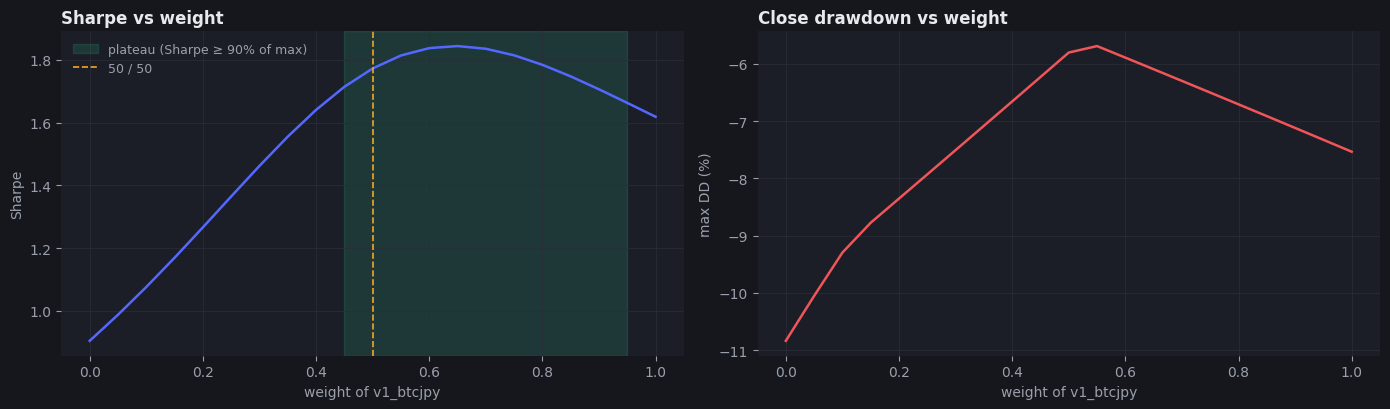

Plateau of v1_btcjpy weight: 45% – 95% | max at 65%


In [ ]:
PLATEAU = None
if N == 2:
    g = np.linspace(0, 1, 21); sh = np.array([pm([1 - x, x])["sharpe"] for x in g]); dd = np.array([pm([1 - x, x])["maxdd"] for x in g])
    ok = sh >= sh.max() * (1 - PLATEAU_TOL); PLATEAU = (g[ok].min(), g[ok].max())
    fig, ax = figs(1, 2, (14, 4.2))
    ax[0].plot(g, sh, color=BLUE, lw=1.8); ax[0].axvspan(*PLATEAU, color=GREEN, alpha=.15, label=f"plateau (Sharpe ≥ {1 - PLATEAU_TOL:.0%} of max)")
    ax[0].axvline(0.5, color=ORANGE, ls="--", lw=1.2, label="50 / 50"); ttl(ax[0], "Sharpe vs weight"); lab(ax[0], f"weight of {keys[1]}", "Sharpe"); leg(ax[0])
    ax[1].plot(g, dd * 100, color=RED, lw=1.8); ttl(ax[1], "Close drawdown vs weight"); lab(ax[1], f"weight of {keys[1]}", "max DD (%)")
    plt.tight_layout(); plt.show(); print(f"Plateau of {keys[1]} weight: {PLATEAU[0]:.0%} – {PLATEAU[1]:.0%} | max at {g[sh.argmax()]:.0%}")
else: print("N > 2: read the shape from the stability table (section 7).")

## 7. WEIGHT STABILITY (block bootstrap)
How much would the max-Sharpe weight change if history had been different? If the 5-95 interval is wide, the tilt is **not identified** and the risk-based base is used.

,median,p5,p95,width
v1_axi_usdjpy,41.5%,17.6%,53.1%,35.5%
v1_btcjpy,58.5%,46.9%,82.4%,35.5%


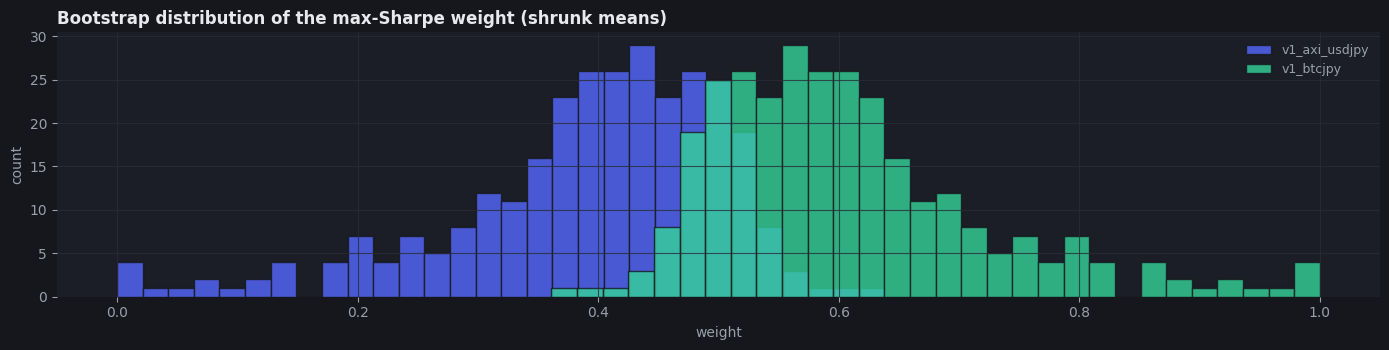

5-95 widths: {'v1_axi_usdjpy': '35%', 'v1_btcjpy': '35%'} -> tilt identified: blended
In-sample Sharpe at the final weight 1.81 vs grid max 1.84: giving up 2% to avoid leaning on unidentified means.
FINAL RISK WEIGHTS: {'v1_axi_usdjpy': '45.8%', 'v1_btcjpy': '54.2%'}
   [PASS] final weights sum to 1 and are >= 0  ->  {'v1_axi_usdjpy': 0.458, 'v1_btcjpy': 0.542}


'PASS'

In [ ]:
rng = np.random.default_rng(SEED); bi = block_idx(len(V), len(V), BLOCK_DAYS, rng, N_BOOT)
Wb = pd.DataFrame([w_maxsr(V.values[i].mean(0) * PPY, shrink_cov(np.cov(V.values[i].T) * PPY)) for i in bi], columns=keys)
st = pd.DataFrame({"median": Wb.median(), "p5": Wb.quantile(.05), "p95": Wb.quantile(.95)}); st["width"] = st.p95 - st.p5; display(st.style.format("{:.1%}"))
fig, ax = figs(1, 1, (14, 3.6))
for i, k in enumerate(keys): ax.hist(Wb[k], bins=30, color=PAL[i % len(PAL)], alpha=0.8, edgecolor=BG, label=k)
ttl(ax, "Bootstrap distribution of the max-Sharpe weight (shrunk means)"); lab(ax, "weight", "count"); leg(ax); plt.tight_layout(); plt.show()
IDENT = bool((st["width"] < W_IDENT_WIDTH).all()); BLEND = BLEND_IF_IDENT if IDENT else 0.0
w_tilt = (st["median"] / st["median"].sum()).values; W_FINAL = pd.Series((1 - BLEND) * W["erc"].values + BLEND * w_tilt, index=keys)
wd = {k: f"{st.loc[k, 'width']:.0%}" for k in keys}
print(f"5-95 widths: {wd} -> " + ("tilt identified: blended" if IDENT else "NOT identified: risk-based base (that is the rule, not a failure)"))
if N == 2:
    s_f = pm([1 - W_FINAL.iloc[1], W_FINAL.iloc[1]])["sharpe"]; s_b = sh.max()
    print(f"In-sample Sharpe at the final weight {s_f:.2f} vs grid max {s_b:.2f}: giving up {1 - s_f / s_b:.0%} to avoid leaning on unidentified means.")
print("FINAL RISK WEIGHTS:", {k: f"{W_FINAL[k]:.1%}" for k in keys})
check("7. Weights", "final weights sum to 1 and are >= 0", abs(W_FINAL.sum() - 1) < 1e-9 and (W_FINAL >= 0).all(), str({k: round(float(v), 3) for k, v in W_FINAL.items()}))

## 8. RISK BUDGET: FROM WEIGHTS TO `size_fraction`
1. **`L` by intrabar Monte Carlo:** resample day blocks, find the largest `L` with `P(intrabar DD < −HARD_LIMIT) ≤ MC_BREACH_MAX` over `MC_YEARS` (intrabar ≈ close DD × `INTRABAR_FACTOR`).
2. **Per-edge caps:** no edge exceeds the size it was validated at (`max_frac`); a binding cap shifts the risk split.
3. **Final check** with the exposures that actually result.

,risk_weight,size_fraction_final,configured_today,validated_cap,change_vs_today,notional_USD
v1_axi_usdjpy,45.8%,1.821x,2.50x,4.37x,-27%,"18,206"
v1_btcjpy,54.2%,0.230x,0.20x,0.30x,+15%,"2,302"


L (hard limit only, MC) = 0.61 | binding caps: none

Final portfolio vs current configuration (common window + intrabar Monte Carlo):


,ann_ret,vol,sharpe,cagr,maxdd,p_breach,dd_p50,dd_p5,ret_p5
final,7.8%,4.3%,1.81,8.1%,-3.46%,5.0%,-4.57%,-8.00%,11.3%
today (configured),8.1%,4.8%,1.68,8.3%,-4.32%,14.8%,-5.54%,-10.02%,10.2%


   [PASS] P(touching -8%) <= 5% at final sizes  ->  5.0%
   [PASS] historical close DD x intrabar factor inside the hard limit  ->  4.32% vs 8%
   [PASS] p5 of 3-year return > 0  ->  11.3%
   [PASS] no edge above its validated size  ->  clipped: none


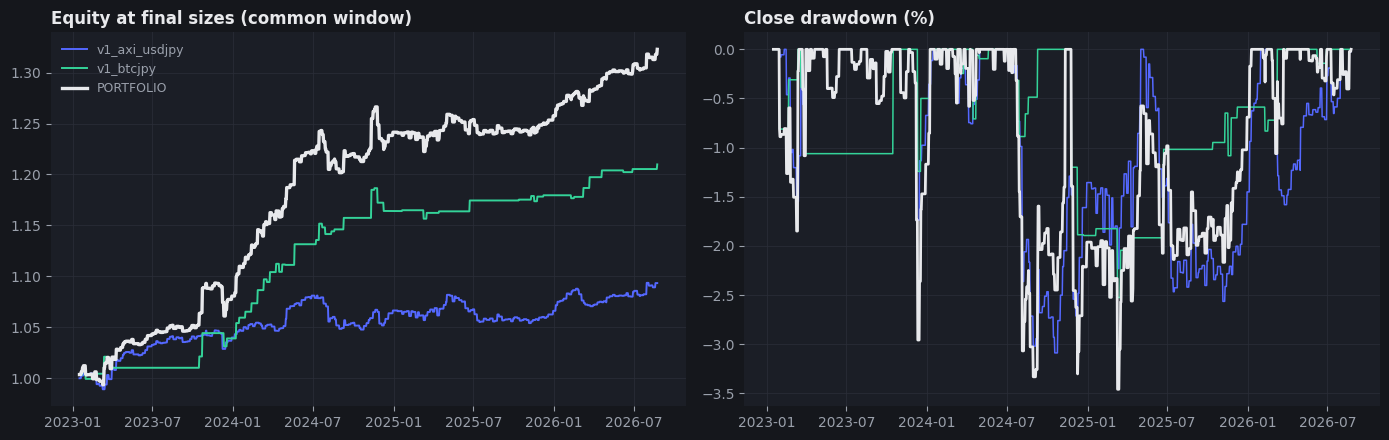

In [ ]:
H = int(MC_YEARS * PPY); MC_IDX = block_idx(len(U), H, BLOCK_DAYS, np.random.default_rng(SEED + 1), N_MC)
def mc_stats(daily):
    eq = np.cumprod(1 + np.asarray(daily)[MC_IDX], axis=1); pk = np.maximum.accumulate(np.maximum(eq, 1.0), axis=1)
    dd = (eq / pk - 1).min(axis=1) * INTRABAR_FACTOR
    return dict(p_breach=float((dd < -HARD_LIMIT).mean()), dd_p50=float(np.median(dd)), dd_p5=float(np.percentile(dd, 5)), ret_p5=float(np.percentile(eq[:, -1] - 1, 5)))
pw = V.values @ W_FINAL.values; lo, hi = 0.0, 50.0
for _ in range(40):
    mid = (lo + hi) / 2
    if mc_stats(mid * pw)["p_breach"] <= MC_BREACH_MAX: lo = mid
    else: hi = mid
L_MC = lo; E_RAW = L_MC * W_FINAL.values * SCALE.values; caps = np.array([SL[k]["max_frac"] for k in keys])
E_FINAL = pd.Series(np.minimum(E_RAW, caps), index=keys); bind = [k for k, e, c in zip(keys, E_RAW, caps) if e > c]
tab = pd.DataFrame({"risk_weight": W_FINAL, "size_fraction_final": E_FINAL, "configured_today": pd.Series({k: SL[k]["frac"] for k in keys}), "validated_cap": pd.Series(dict(zip(keys, caps)))})
tab["change_vs_today"] = tab.size_fraction_final / tab.configured_today - 1; tab["notional_USD"] = tab.size_fraction_final * CAPITAL
display(tab.style.format({"risk_weight": "{:.1%}", "size_fraction_final": "{:.3f}x", "configured_today": "{:.2f}x", "validated_cap": "{:.2f}x", "change_vs_today": "{:+.0%}", "notional_USD": "{:,.0f}"}))
print(f"L (hard limit only, MC) = {L_MC:.2f} | binding caps: {bind or 'none'}")
daily_final, daily_today = (U * E_FINAL).sum(axis=1), (U * cfg_exp).sum(axis=1)
cmp = pd.DataFrame({"final": {**perf(daily_final), **mc_stats(daily_final.values)}, "today (configured)": {**perf(daily_today), **mc_stats(daily_today.values)}}).T
print("\nFinal portfolio vs current configuration (common window + intrabar Monte Carlo):")
display(cmp[["ann_ret", "vol", "sharpe", "cagr", "maxdd", "p_breach", "dd_p50", "dd_p5", "ret_p5"]].style.format({**F, "p_breach": "{:.1%}", "dd_p50": "{:.2%}", "dd_p5": "{:.2%}", "ret_p5": "{:.1%}"}))
fin, pf = mc_stats(daily_final.values), perf(daily_final)
check("8. Risk", f"P(touching -{HARD_LIMIT:.0%}) <= {MC_BREACH_MAX:.0%} at final sizes", fin["p_breach"] <= MC_BREACH_MAX, f"{fin['p_breach']:.1%}")
check("8. Risk", "historical close DD x intrabar factor inside the hard limit", abs(pf["maxdd"]) * INTRABAR_FACTOR < HARD_LIMIT, f"{abs(pf['maxdd']) * INTRABAR_FACTOR:.2%} vs {HARD_LIMIT:.0%}")
check("8. Risk", f"p5 of {MC_YEARS}-year return > 0", fin["ret_p5"] > 0, f"{fin['ret_p5']:.1%}")
check("8. Risk", "no edge above its validated size", bool((E_FINAL <= caps + 1e-12).all()), f"clipped: {bind or 'none'}")

eqs = pd.DataFrame({k: (1 + U[k] * E_FINAL[k]).cumprod() for k in keys}); eqs["PORTFOLIO"] = (1 + daily_final).cumprod()
fig, ax = figs(1, 2, (14, 4.5))
for i, c in enumerate(eqs.columns):
    p = c == "PORTFOLIO"; col = TXT if p else PAL[i % len(PAL)]
    ax[0].plot(eqs.index, eqs[c], color=col, lw=2.4 if p else 1.4, label=c); ax[1].plot(eqs.index, (eqs[c] / eqs[c].cummax() - 1) * 100, color=col, lw=2.0 if p else 1.1, label=c)
ttl(ax[0], "Equity at final sizes (common window)"); leg(ax[0], "upper left"); ttl(ax[1], "Close drawdown (%)"); plt.tight_layout(); plt.show()

## 9. COMPOUNDING EFFECT (Guide §8)
`compound ≈ mean − variance/2`. The fair comparison is **at equal risk**: each edge alone scaled to the portfolio's vol vs the portfolio. The gap is `(Sharpe_portfolio − Sharpe_edge) · σ_portfolio`: what diversifying earns, not what betting harder earns.

In [ ]:
sp = pf["vol"]; rows = {"PORTFOLIO": dict(arith_mean=pf["ann_ret"], vol=sp, half_var=sp ** 2 / 2, compound_approx=pf["ann_ret"] - sp ** 2 / 2, sharpe=pf["sharpe"])}
for k in keys:
    p = perf(U[k] * E_FINAL[k]); m = p["ann_ret"] * sp / p["vol"]
    rows[f"{k} alone, same vol"] = dict(arith_mean=m, vol=sp, half_var=sp ** 2 / 2, compound_approx=m - sp ** 2 / 2, sharpe=p["sharpe"])
display(pd.DataFrame(rows).T.style.format({"arith_mean": "{:.2%}", "vol": "{:.2%}", "half_var": "{:.2%}", "compound_approx": "{:.2%}", "sharpe": "{:.2f}"}))
sr = [perf(U[k] * E_FINAL[k])["sharpe"] for k in keys]
check("9. Compounding", "portfolio Sharpe >= mean Sharpe of its edges (diversification adds)", pf["sharpe"] >= np.mean(sr) - 1e-9, f"{pf['sharpe']:.2f} vs {np.mean(sr):.2f} (best edge {max(sr):.2f})")

,arith_mean,vol,half_var,compound_approx,sharpe
PORTFOLIO,7.85%,4.34%,0.09%,7.75%,1.81
"v1_axi_usdjpy alone, same vol",3.92%,4.34%,0.09%,3.83%,0.90
"v1_btcjpy alone, same vol",7.02%,4.34%,0.09%,6.93%,1.62


   [PASS] portfolio Sharpe >= mean Sharpe of its edges (diversification adds)  ->  1.81 vs 1.26 (best edge 1.62)


'PASS'

## 10. STRESS (Guide §2.3: correlation jumps to +1 when you need it low)
Diversification cuts normal risk, **not tail risk**. (1) every edge has its worst day on the same day, (2) twice that, (3) one edge dies (edge decay), same sizes.

In [ ]:
l1 = float((E_FINAL * U.min()).sum())
display(pd.DataFrame([dict(scenario="Worst day of every edge, same day", loss=l1, intrabar=l1 * INTRABAR_FACTOR),
                      dict(scenario="2 x worst day of every edge, same day", loss=2 * l1, intrabar=2 * l1 * INTRABAR_FACTOR)]).style.format({"loss": "{:.2%}", "intrabar": "{:.2%}"}))
check("10. Stress", "simultaneous worst day (intrabar) inside the hard limit", abs(l1) * INTRABAR_FACTOR < HARD_LIMIT, f"{l1 * INTRABAR_FACTOR:.2%} vs -{HARD_LIMIT:.0%}")
rows = {}
for d in keys:
    keep = [k for k in keys if k != d]; p = perf((U[keep] * E_FINAL[keep]).sum(axis=1))
    rows[f"without {d}"] = dict(sharpe=p["sharpe"], cagr=p["cagr"], maxdd=p["maxdd"], return_it_contributed=1 - p["ann_ret"] / pf["ann_ret"])
rows["full portfolio"] = dict(sharpe=pf["sharpe"], cagr=pf["cagr"], maxdd=pf["maxdd"], return_it_contributed=np.nan)
display(pd.DataFrame(rows).T.style.format({"sharpe": "{:.2f}", "cagr": "{:.1%}", "maxdd": "{:.2%}", "return_it_contributed": "{:.0%}"}))
print("'return_it_contributed' = share of mean portfolio return lost when that edge is removed; if one edge carries almost everything, the portfolio is one bet.")

,scenario,loss,intrabar
0,"Worst day of every edge, same day",-2.64%,-3.30%
1,"2 x worst day of every edge, same day",-5.28%,-6.60%


   [PASS] simultaneous worst day (intrabar) inside the hard limit  ->  -3.30% vs -8%


,sharpe,cagr,maxdd,return_it_contributed
without v1_axi_usdjpy,1.62,5.4%,-2.52%,32%
without v1_btcjpy,0.90,2.5%,-3.09%,68%
full portfolio,1.81,8.1%,-3.46%,nan%


'return_it_contributed' = share of mean portfolio return lost when that edge is removed; if one edge carries almost everything, the portfolio is one bet.


## 11. WALK-FORWARD OF THE WEIGHTS
For each year `Y`, `SCALE` and weights are estimated on data **before** `Y`, applied to `Y`, and the OOS results are chained. With few years it is **descriptive**.

In [ ]:
def wf_w(Utr, n):
    s = TARGET_VOL / (Utr.std() * np.sqrt(PPY)); Vt = Utr * s
    return SCHEMES[n](Vt.mean().values * PPY, shrink_cov(Vt.cov().values * PPY)), s
oos = {n: [] for n in ("erc", "max_sharpe_shrunk", "as_configured")}; wp = []
for y in sorted(set(U.index.year)):
    tr, te = U[U.index < f"{y}-01-01"], U[U.index.year == y]
    if len(tr) < MIN_TRAIN_YEARS * PPY or len(te) < 30: continue
    for n in ("erc", "max_sharpe_shrunk"):
        w, s = wf_w(tr, n); oos[n].append(pd.Series(te.values @ (w * s.values), index=te.index))
        if n == "erc": wp.append(dict(year=y, **{k: w[i] for i, k in enumerate(keys)}, train_days=len(tr)))
    oos["as_configured"].append(te @ pd.Series(cfg_exp, index=keys))
if not wp: print("Not enough prior history for any fold."); check("11. Walk-forward", "walk-forward weights evaluable", None, "insufficient history")
else:
    print(f"{len(wp)} yearly OOS fold(s) | ERC weights by year:"); display(pd.DataFrame(wp).set_index("year").style.format({k: "{:.0%}" for k in keys}))
    res = {n: perf(pd.concat(v)) for n, v in oos.items()}
    display(pd.DataFrame(res).T[["years", "ann_ret", "vol", "sharpe", "maxdd"]].style.format(F))
    print("Vols differ across schemes (as_configured is not normalised): compare Sharpe, not return.")
    check("11. Walk-forward", "OOS Sharpe of ERC (weights without looking ahead) > 0", res["erc"]["sharpe"] > 0, f"{res['erc']['sharpe']:.2f} over {len(wp)} fold(s)")
    print(f"Informative: OOS Sharpe ERC {res['erc']['sharpe']:.2f} | as_configured {res['as_configured']['sharpe']:.2f} | max_sharpe_shrunk {res['max_sharpe_shrunk']['sharpe']:.2f} (does not decide anything on its own).")

2 yearly OOS fold(s) | ERC weights by year:


,v1_axi_usdjpy,v1_btcjpy,train_days
year,,,
2025,50%,50%,716
2026,50%,50%,1081


,years,ann_ret,vol,sharpe,maxdd
erc,1.65,5.8%,4.6%,1.27,-3.05%
max_sharpe_shrunk,1.65,5.9%,4.2%,1.41,-2.21%
as_configured,1.65,4.2%,3.6%,1.14,-2.68%


Vols differ across schemes (as_configured is not normalised): compare Sharpe, not return.
   [PASS] OOS Sharpe of ERC (weights without looking ahead) > 0  ->  1.27 over 2 fold(s)
Informative: OOS Sharpe ERC 1.27 | as_configured 1.14 | max_sharpe_shrunk 1.41 (does not decide anything on its own).


## 12. VERDICT AND SAVE

In [ ]:
print("=" * 78 + "\nPASS / FAIL SUMMARY" + "" + "\n" + "=" * 78)
for sec in dict.fromkeys(c["section"] for c in CHECKS):
    print(f"\n{sec}")
    for c in [c for c in CHECKS if c["section"] == sec]: print(f"  [{c['status']}] {c['name']}" + (f"  ->  {c['detail']}" if c["detail"] else ""))
fails = [c for c in CHECKS if c["status"] == "FAIL"]
print("\n" + "=" * 78 + "\nSIZE PLAN (paste into risk.size_fraction of each variant, then re-run that edge's notebook 04 for lots):")
for k in keys: print(f"  {k:<10} {SL[k]['name']:<28} size_fraction = {E_FINAL[k]:.3f} (today {SL[k]['frac']:.2f}) | risk weight {W_FINAL[k]:.0%} | ~{E_FINAL[k] * CAPITAL:,.0f} USD notional")
print("OVERALL: " + ("PASS" if not fails else f"{len(fails)} FAIL -> document each before trading (a margin or exception is declared, not applied silently)") + "\n" + "=" * 78)
P = dict(portfolio_id=PORTFOLIO_ID, hypothesis=HYPOTHESIS, window=[str(START.date()), str(END.date())], capital=CAPITAL, hard_limit=HARD_LIMIT,
         edges={k: dict(id=SL[k]["name"], source=SL[k]["source"], risk_weight=float(W_FINAL[k]), size_fraction=float(E_FINAL[k]), configured=SL[k]["frac"]) for k in keys},
         L_hard_limit=float(L_MC), binding_caps=bind, tilt_identified=bool(IDENT), blend=float(BLEND), schemes_compared=len(SCHEMES),
         params=dict(TARGET_VOL=TARGET_VOL, PRIOR_RHO=PRIOR_RHO, SHRINK_RHO=SHRINK_RHO, MEAN_SHRINK=MEAN_SHRINK, INTRABAR_FACTOR=INTRABAR_FACTOR,
                     BLOCK_DAYS=BLOCK_DAYS, MC_YEARS=MC_YEARS, MC_BREACH_MAX=MC_BREACH_MAX, N_BOOT=N_BOOT, N_MC=N_MC, SEED=SEED), checks=CHECKS)
P["params_hash"] = hashlib.sha1(json.dumps(P["params"], sort_keys=True).encode()).hexdigest()[:8]
out = OUT_DIR / "portfolio.json"; out.write_text(json.dumps(P, indent=2, default=str)); print("Saved:", out)

PASS / FAIL SUMMARY

2. Data
  [PASS] common window >= 2 years  ->  3.61

4. Correlation
  [PASS] v1_axi_usdjpy/v1_btcjpy: weekly corr estimable (>= 30 co-active weeks)  ->  52 co-active weeks
  [PASS] v1_axi_usdjpy/v1_btcjpy: weekly corr < 0.5  ->  +0.07 (CI90 -0.06..+0.21)
  [PASS] structural reason declared (WHY_UNCORRELATED)  ->  see EXPERIMENT
  [SKIP] shared JPY factor measured  ->  set JPY_PROXY_CSV

7. Weights
  [PASS] final weights sum to 1 and are >= 0  ->  {'v1_axi_usdjpy': 0.458, 'v1_btcjpy': 0.542}

8. Risk
  [PASS] P(touching -8%) <= 5% at final sizes  ->  5.0%
  [PASS] historical close DD x intrabar factor inside the hard limit  ->  4.32% vs 8%
  [PASS] p5 of 3-year return > 0  ->  11.3%
  [PASS] no edge above its validated size  ->  clipped: none

9. Compounding
  [PASS] portfolio Sharpe >= mean Sharpe of its edges (diversification adds)  ->  1.81 vs 1.26 (best edge 1.62)

10. Stress
  [PASS] simultaneous worst day (intrabar) inside the hard limit  ->  -3.30% vs -8%

11

## ADDING A NEW TYPE OF EDGE

A new variant of an existing edge (Gotobi, Monday, RSI2) needs no code: add its name to `EDGES`.
A **new type** of edge needs this, once.

**1. At the end of the edge's notebook 03/04**, where `ret` (daily returns, net of costs), `FRAC`, `RUN_DIR`, `EDGE_DIR` and `VARIANT` exist:

```python
import json, hashlib
from pathlib import Path
import pandas as pd

yaml_path = Path(EDGE_DIR) / "variants" / f"{VARIANT}.yaml"
csv = Path(RUN_DIR) / "daily_returns.csv"
pd.Series(ret, name="ret").to_csv(csv, index_label="date")
Path(str(csv) + ".meta.json").write_text(json.dumps(dict(
    frac=float(FRAC),                                              # size at which `ret` was computed
    yaml_sha=hashlib.sha1(yaml_path.read_bytes()).hexdigest()[:10])))
```

**2. `FRAC`** is the unit of the final `size_fraction`: the edge's own `size_fraction` if it sizes by capital fraction, or `1.0` (official sizing) if it sizes by risk, so the output is a multiple of it.

**3. Here:** add the variant to `EDGES`, `MAX_SIZE` if it has a validated cap, update `WHY_UNCORRELATED`, Run All.

Re-export after any YAML change (the notebook stops if the hash differs).